In [1]:

import pandas as pd

# Satış verilerini yükle
df = pd.read_csv("../mart_sales.csv")

# İlk 5 satırı göster
df.head()


,Order_ID,Customer_ID,Date,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method
0,ORD_000001-1,CUST_00001,2023-05-29,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet
1,ORD_000001-2,CUST_00001,2023-10-12,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card
2,ORD_000001-3,CUST_00001,2023-12-05,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card
3,ORD_000002-1,CUST_00002,2023-05-11,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet
4,ORD_000002-2,CUST_00002,2023-06-16,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card


In [2]:

print("Toplam satır sayısı:", df.shape[0])
print("Toplam sütun sayısı:", df.shape[1])

print("\nEksik veri sayıları:")
print(df.isnull().sum())

print("\nTekrarlanan satır sayısı:", df.duplicated().sum())


Toplam satır sayısı: 17049
Toplam sütun sayısı: 10

Eksik veri sayıları:
Order_ID            0
Customer_ID         0
Date                0
City                0
Product_Category    0
Unit_Price          0
Quantity            0
Discount_Amount     0
Total_Amount        0
Payment_Method      0
dtype: int64

Tekrarlanan satır sayısı: 0


In [4]:

# Ürün kategorilerine göre toplam satış tutarı
kategori_satis = (
    df.groupby("Product_Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Ürün kategorilerine göre toplam satış:")
print(kategori_satis)


Ürün kategorilerine göre toplam satış:
Product_Category
Electronics      10481897.65
Home & Garden     4023903.94
Sports            3205086.99
Fashion           1577035.70
Toys              1014237.53
Beauty             694437.02
Food               422054.65
Books              360399.11
Name: Total_Amount, dtype: float64


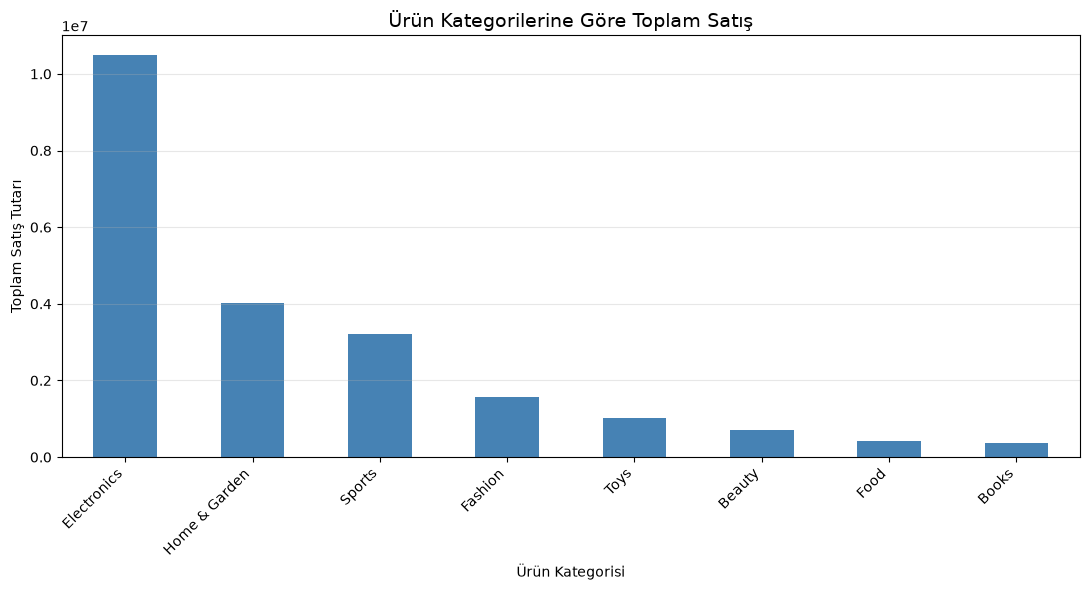

In [5]:

import matplotlib.pyplot as plt

# Ürün kategorilerine göre toplam satış grafiği
plt.figure(figsize=(11, 6))

kategori_satis.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Ürün Kategorilerine Göre Toplam Satış", fontsize=14)
plt.xlabel("Ürün Kategorisi")
plt.ylabel("Toplam Satış Tutarı")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Ödeme Yöntemlerine Göre Sipariş Sayıları:
Payment_Method
Credit Card         6801
Debit Card          4321
Digital Wallet      3276
Bank Transfer       1763
Cash on Delivery     888
Name: count, dtype: int64


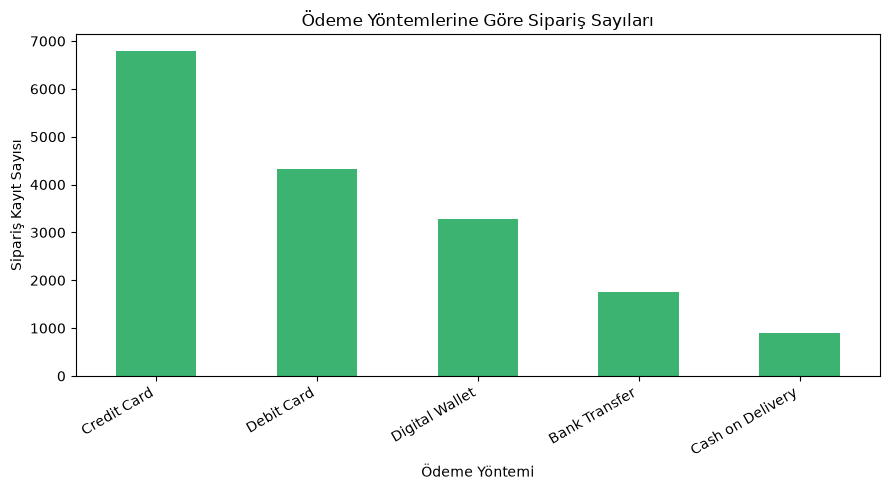

In [6]:

# Ödeme yöntemlerine göre sipariş kayıt sayısı
odeme_analizi = df["Payment_Method"].value_counts()

print("Ödeme Yöntemlerine Göre Sipariş Sayıları:")
print(odeme_analizi)

# Grafik
plt.figure(figsize=(9, 5))
odeme_analizi.plot(kind="bar", color="mediumseagreen")

plt.title("Ödeme Yöntemlerine Göre Sipariş Sayıları")
plt.xlabel("Ödeme Yöntemi")
plt.ylabel("Sipariş Kayıt Sayısı")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Müşteri Puanlarına Göre Kayıt Sayıları:
Customer_Rating
1     781
2    1487
3    2658
4    5863
5    6260
Name: count, dtype: int64

Ortalama Müşteri Puanı: 3.9


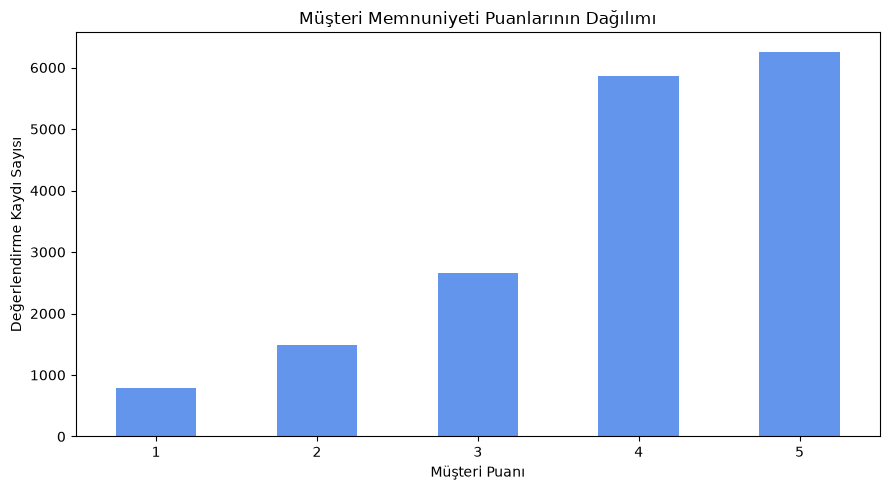

In [7]:

# Müşteri memnuniyeti verilerini yükle
memnuniyet_df = pd.read_csv("../mart_satisfaction.csv")

# Müşteri puanlarına göre kayıt sayısı
puanlar = (
    memnuniyet_df["Customer_Rating"]
    .value_counts()
    .sort_index()
)

print("Müşteri Puanlarına Göre Kayıt Sayıları:")
print(puanlar)

print(
    "\nOrtalama Müşteri Puanı:",
    round(memnuniyet_df["Customer_Rating"].mean(), 2)
)

# Müşteri puanları grafiği
plt.figure(figsize=(9, 5))
puanlar.plot(kind="bar", color="cornflowerblue")

plt.title("Müşteri Memnuniyeti Puanlarının Dağılımı")
plt.xlabel("Müşteri Puanı")
plt.ylabel("Değerlendirme Kaydı Sayısı")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## Analiz Sonuçları ve Değerlendirme

Bu çalışmada 17.049 kayıt ve 10 sütun içeren satış verileri
Python kullanılarak analiz edilmiştir.

### 1. Veri Kalitesi
İncelenen satış tablosunda eksik değer ve birebir
tekrarlanan satır tespit edilmemiştir.

### 2. Satış Performansı
En yüksek toplam satış tutarı Electronics kategorisinde
gerçekleşmiştir. Home & Garden ve Sports kategorileri
bu kategoriyi takip etmektedir.

### 3. Müşteri Davranışları
En yaygın ödeme yöntemi kredi kartıdır.
Kredi kartı ile gerçekleştirilen 6.801 sipariş kaydı,
toplam kayıtların yaklaşık %40'ını oluşturmaktadır.

### 4. Müşteri Memnuniyeti
Ortalama müşteri değerlendirme puanı 5 üzerinden 3,90'dır.
Değerlendirmelerin büyük bölümü 4 ve 5 puanda yoğunlaşmıştır.

### Genel Sonuç
Analizler, elektronik ürünlerin satış performansında
öne çıktığını, kredi kartının yaygın kullanıldığını ve
müşteri değerlendirmelerinin genel olarak olumlu olduğunu
göstermektedir.

Bu bulgular, satış stratejilerinin geliştirilmesi ve
müşteri deneyiminin iyileştirilmesi için karar desteği
sağlayabilir.
